### 이상탐지를 위한 라이브러리 설치

In [16]:
!pip install anomalib
!pip install pytorch-lightning

  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.0/45.0 kB 5.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 76.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 246.1/246.1 kB 30.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 88.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 849.3/849.3 kB 71.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 82.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 28.4/28.4 MB 75.3 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.3/5.3 MB 113.5 MB/s eta 0:00:0000:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 803.9/803.9 kB 69.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 853.0/853.0 kB 70.0 MB/s eta 0:00:00
  Created wheel for freia: filename=freia-0.2-py3-none-any.whl size=42848 sha256=aafe8635b7d8302021cc20f65129c6b98cd188c4f37b35e35a988d18907032c3
 

In [17]:
!pip install wget

  Preparing metadata (setup.py) ... done
  Created wheel for wget: filename=wget-3.2-py3-none-any.whl size=9686 sha256=c39378d6926fe6513aa9126792486a86c5da170b55813a66cfca307cfe7c73b3
  Stored in directory: /root/.cache/pip/wheels/8a/b8/04/0c88fb22489b0c049bee4e977c5689c7fe597d6c4b0e7d0b6a
Successfully built wget


## VisA 데이터셋 다운로드

In [18]:
import os
import wget
import zipfile
from pathlib import Path
import pandas as pd
import tarfile

def download_visa_dataset():
    """VisA 데이터셋 다운로드"""
    base_url = "https://amazon-visual-anomaly.s3.us-west-2.amazonaws.com/VisA_20220922.tar"
    filename = "VisA_20220922.tar"
    extract_dir = "./VisA"


    if not os.path.exists(filename):
        print("VisA 데이터셋 다운로드 중...")
        wget.download(base_url, filename)
        print("\n다운로드 완료!")

    ## 압축 해제
    if not os.path.exists(extract_dir):
        os.makedirs(extract_dir, exist_ok=True)
        with tarfile.open(filename, 'r') as tar:
            tar.extractall(path=extract_dir)
        print("압축 해제 완료!")

def check_visa_structure(data_path="./VisA_pytorch/VisA"):
    """VisA 데이터셋 구조 확인"""
    data_path = Path(data_path)
    print(f"VisA 데이터셋 경로: {data_path}")

    categories = []
    for category_dir in data_path.iterdir():
        if category_dir.is_dir():
            categories.append(category_dir.name)
            print(f"\n카테고리: {category_dir.name}")

            # 이미지 개수 확인
            images_dir = category_dir / "Data" / "Images"
            if images_dir.exists():
                normal_count = len(list((images_dir / "Normal").glob("*"))) if (images_dir / "Normal").exists() else 0


                print(f"  정상 이미지: {normal_count}개")

    return categories

In [19]:
download_visa_dataset()

VisA 데이터셋 다운로드 중...

다운로드 완료!


/tmp/ipykernel_17332/1396103325.py:24: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extractall(path=extract_dir)


압축 해제 완료!


In [20]:
check_visa_structure(data_path="./VisA")

VisA 데이터셋 경로: VisA

카테고리: split_csv

카테고리: pipe_fryum
  정상 이미지: 500개

카테고리: cashew
  정상 이미지: 500개

카테고리: pcb1
  정상 이미지: 1004개

카테고리: pcb3
  정상 이미지: 1006개

카테고리: macaroni2
  정상 이미지: 1000개

카테고리: pcb4
  정상 이미지: 1005개

카테고리: candle
  정상 이미지: 1000개

카테고리: capsules
  정상 이미지: 602개

카테고리: fryum
  정상 이미지: 500개

카테고리: macaroni1
  정상 이미지: 1000개

카테고리: chewinggum
  정상 이미지: 503개

카테고리: pcb2
  정상 이미지: 1001개


['split_csv',
 'pipe_fryum',
 'cashew',
 'pcb1',
 'pcb3',
 'macaroni2',
 'pcb4',
 'candle',
 'capsules',
 'fryum',
 'macaroni1',
 'chewinggum',
 'pcb2']

### Dataloader 구현

이 코드에서는 정상 이미지를 이용해 정상 상태의 특징을 학습하고, 테스트할 때 정상과 비정상 이미지를 함께 사용한다. 정상과 불량을 모두 학습하는 이진 분류와 달리, 정상 패턴에서 얼마나 벗어나는지를 이용해 이상을 탐지하는 방식이다. 다양한 불량 사례를 충분히 수집하기 어려운 상황을 가정한 구성으로 이해했다.

In [21]:
import torch
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import torchvision.transforms as transforms
import cv2
import numpy as np

class VisADataset(Dataset):
    def __init__(self, data_path, category, transform=None, is_train=True, include_mask=False, train_ratio=0.8):
        self.data_path = Path(data_path)
        self.category = category
        self.transform = transform
        self.is_train = is_train
        self.include_mask = include_mask

        self.image_paths = []
        self.mask_paths = []
        self.labels = []
        self.defect_types = []

        category_path = self.data_path / category

        # CSV 파일에서 메타데이터 로드
        csv_path = category_path / "image_anno.csv"
        if csv_path.exists():
            df = pd.read_csv(csv_path)
            print(f"CSV 컬럼: {df.columns.tolist()}")

            # 정상/비정상 데이터 분리
            normal_df = df[df['label'] == 'normal'].copy()
            anomaly_df = df[df['label'] != 'normal'].copy()

            if self.is_train:
                # 훈련용: 정상 데이터의 일부만 사용
                # 정상 데이터만 학습에 사용해 정상 상태의 패턴을 추정한다.
                # CSV 순서대로 앞부분을 선택하므로 데이터 정렬 순서가 분할에 영향을 준다.
                train_size = int(len(normal_df) * train_ratio)
                selected_df = normal_df.iloc[:train_size]
                print(f"훈련용 정상 데이터: {len(selected_df)}개")
            else:
                # 테스트용: 나머지 정상 데이터 + 모든 비정상 데이터
                test_normal_size = len(normal_df) - int(len(normal_df) * train_ratio)
                test_normal_df = normal_df.iloc[-test_normal_size:] if test_normal_size > 0 else pd.DataFrame()
                selected_df = pd.concat([test_normal_df, anomaly_df], ignore_index=True)
                print(f"테스트용 정상 데이터: {len(test_normal_df)}개")
                print(f"테스트용 비정상 데이터: {len(anomaly_df)}개")

            # 데이터 로드
            for _, row in selected_df.iterrows():
                # 이미지 경로 처리 (중복 경로 제거)
                image_rel_path = row['image']
                if image_rel_path.startswith(category + '/'):
                    image_path = self.data_path / image_rel_path
                else:
                    image_path = category_path / image_rel_path

                if image_path.exists():
                    self.image_paths.append(str(image_path))
                    self.labels.append(0 if row['label'] == 'normal' else 1)
                    self.defect_types.append(row['label'])

                    # 마스크 경로 처리
                    if pd.notna(row['mask']) and self.include_mask:
                        mask_rel_path = row['mask']
                        if mask_rel_path.startswith(category + '/'):
                            mask_path = self.data_path / mask_rel_path
                        else:
                            mask_path = category_path / mask_rel_path
                        self.mask_paths.append(str(mask_path) if mask_path.exists() else None)
                    else:
                        self.mask_paths.append(None)
                else:
                    print(f"이미지 파일을 찾을 수 없습니다: {image_path}")
        else:
            print("CSV 파일이 없습니다. 폴더 구조를 기반으로 데이터를 로드합니다.")
            self._load_from_folder_structure()

    def _load_from_folder_structure(self):
        """폴더 구조를 기반으로 데이터 로드 (CSV가 없는 경우)"""
        category_path = self.data_path / self.category
        images_path = category_path / "Data" / "Images"
        masks_path = category_path / "Data" / "Masks"

        # 확인: 폴더 기반 로딩에서는 train_ratio로 정상 이미지를 나누지 않는다.
        # 아래 테스트 로딩에서도 같은 Normal 폴더를 사용하므로 학습/테스트 중복을 확인해야 한다.
        if self.is_train:
            # 훈련용: 정상 이미지만 사용
            normal_path = images_path / "Normal"
            if normal_path.exists():
                for img_path in normal_path.glob("*"):
                    if img_path.suffix.lower() in ['.jpg', '.jpeg', '.png', '.bmp']:
                        self.image_paths.append(str(img_path))
                        self.labels.append(0)  # 정상: 0
                        self.defect_types.append('normal')
                        self.mask_paths.append(None)
        else:
            # 테스트용: 정상 + 비정상 이미지
            # 정상 이미지
            normal_path = images_path / "Normal"
            if normal_path.exists():
                for img_path in normal_path.glob("*"):
                    if img_path.suffix.lower() in ['.jpg', '.jpeg', '.png', '.bmp']:
                        self.image_paths.append(str(img_path))
                        self.labels.append(0)
                        self.defect_types.append('normal')
                        self.mask_paths.append(None)

            # 비정상 이미지
            anomaly_path = images_path / "Anomaly"
            if anomaly_path.exists():
                for img_path in anomaly_path.glob("*"):
                    if img_path.suffix.lower() in ['.jpg', '.jpeg', '.png', '.bmp']:
                        self.image_paths.append(str(img_path))
                        self.labels.append(1)  # 이상: 1
                        self.defect_types.append('anomaly')

                        # 마스크 경로 찾기
                        if self.include_mask:
                            mask_name = img_path.stem + '.png'  # 확장자를 png로 변경
                            mask_path = masks_path / "Anomaly" / mask_name
                            self.mask_paths.append(str(mask_path) if mask_path.exists() else None)
                        else:
                            self.mask_paths.append(None)

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        # 이미지 로드
        image = Image.open(self.image_paths[idx]).convert('RGB')
        label = self.labels[idx]

        # 마스크 로드 (있는 경우)
        mask = None
        if self.include_mask and self.mask_paths[idx] is not None:
            try:
                mask = Image.open(self.mask_paths[idx]).convert('L')
            except:
                mask = None

        # 변환 적용
        if self.transform:
            image = self.transform(image)
            if mask is not None:
                mask_transform = transforms.Compose([
                    transforms.Resize((256, 256)),
                    transforms.ToTensor()
                ])
                mask = mask_transform(mask)

        result = {
            'image': image,
            'label': label,
            'defect_type': self.defect_types[idx]
        }

        if mask is not None:
            result['mask'] = mask

        return result

다만 CSV 사용 여부에 따라 데이터 분할 방식이 달라지므로 실제로 어느 경로로 데이터가 로드되는지 확인해야 한다.

In [22]:
# 데이터 전처리 정의
def get_visa_transforms():
    train_transform = transforms.Compose([
        transforms.Resize((256, 256)),
        # 정상 이미지의 좌우 반전도 학습에 포함한다.
        # 제품 방향이 중요한 경우, 반전된 이미지도 정상으로 봐도 되는지 검토해야 한다.
        transforms.RandomHorizontalFlip(p=0.5),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406],
                           std=[0.229, 0.224, 0.225])
    ])

    test_transform = transforms.Compose([
        transforms.Resize((256, 256)),
        transforms.ToTensor(),
        # 채널별로 (입력 - 평균) / 표준편차를 계산한다.
        # 정규화 이후에는 음수나 1보다 큰 값도 나올 수 있다.    
        transforms.Normalize(mean=[0.485, 0.456, 0.406],
                           std=[0.229, 0.224, 0.225])
    ])

    return train_transform, test_transform


In [23]:
def create_visa_data_loaders(data_path, category, batch_size=32, include_mask=False, train_ratio=0.8):
    """
    VisA 데이터셋용 데이터 로더 생성

    Args:
        data_path: VisA 데이터셋 경로
        category: 카테고리 이름
        batch_size: 배치 크기
        include_mask: 마스크 포함 여부
        train_ratio: 훈련 데이터 비율 (정상 데이터에서)
    """
    train_transform, test_transform = get_visa_transforms()

    train_dataset = VisADataset(
        data_path, category,
        transform=train_transform,
        is_train=True,
        include_mask=include_mask,
        train_ratio=train_ratio
    )

    test_dataset = VisADataset(
        data_path, category,
        transform=test_transform,
        is_train=False,
        include_mask=include_mask,
        train_ratio=train_ratio
    )

    train_loader = DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True,
        num_workers=2,  # Windows에서 문제가 있을 수 있으므로 낮춤
        pin_memory=True
    )

    test_loader = DataLoader(
        test_dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=2,
        pin_memory=True
    )

    return train_loader, test_loader


## 시각화

In [24]:
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import numpy as np

def visualize_visa_samples(dataset, num_samples=8):
    """VisA 데이터셋 샘플 시각화"""
    fig, axes = plt.subplots(2, 4, figsize=(16, 8))
    axes = axes.flatten()

    indices = np.random.choice(len(dataset), min(num_samples, len(dataset)), replace=False)

    for i, idx in enumerate(indices):
        sample = dataset[idx]
        image = sample['image']
        label = sample['label']
        defect_type = sample['defect_type']

        # 텐서를 이미지로 변환
        if isinstance(image, torch.Tensor):
            # 모델 입력의 [C, H, W]를 시각화에 필요한 [H, W, C]로 변경한다.
            image = image.permute(1, 2, 0)
            # 정규화의 역변환: 원래 값 = 정규화된 값 × 표준편차 + 평균
            image = image * torch.tensor([0.229, 0.224, 0.225]) + torch.tensor([0.485, 0.456, 0.406])
            image = torch.clamp(image, 0, 1)

        axes[i].imshow(image)
        title = f"{'Normal' if label == 0 else 'Anomaly'}"
        if defect_type != 'normal':
            title += f"\n({defect_type})"
        axes[i].set_title(title)
        axes[i].axis('off')

    plt.tight_layout()
    plt.show()

def visualize_with_mask(dataset, idx):
    """이미지와 마스크 함께 시각화"""
    sample = dataset[idx]
    image = sample['image']
    mask = sample.get('mask')
    label = sample['label']
    defect_type = sample['defect_type']

    # 이미지 정규화 해제
    if isinstance(image, torch.Tensor):
        image = image.permute(1, 2, 0)
        image = image * torch.tensor([0.229, 0.224, 0.225]) + torch.tensor([0.485, 0.456, 0.406])
        image = torch.clamp(image, 0, 1)

    if mask is not None:
        fig, axes = plt.subplots(1, 3, figsize=(15, 5))

        # 원본 이미지
        axes[0].imshow(image)
        axes[0].set_title('Original Image')
        axes[0].axis('off')

        # 마스크
        axes[1].imshow(mask.squeeze(), cmap='gray')
        axes[1].set_title('Anomaly Mask')
        axes[1].axis('off')

        # 오버레이
        overlay = image.clone()
        if mask.sum() > 0:
            mask_resized = torch.nn.functional.interpolate(
                mask.unsqueeze(0),
                size=image.shape[:2],
                mode='nearest'
            ).squeeze()
            overlay[mask_resized > 0.01] = torch.tensor([255.0, 0.0, 0.0])  # 빨간색으로 표시

        axes[2].imshow(overlay)
        axes[2].set_title(f'Overlay ({defect_type})')
        axes[2].axis('off')

    else:
        plt.figure(figsize=(8, 6))
        plt.imshow(image)
        plt.title(f"{'Normal' if label == 0 else 'Anomaly'} - {defect_type}")
        plt.axis('off')

    plt.tight_layout()
    plt.show()


In [25]:
def plot_visa_statistics(data_path, category):
    """VisA 데이터셋 통계 시각화"""
    category_path = Path(data_path) / category
    csv_path = category_path / "image_anno.csv"

    if csv_path.exists():
        df = pd.read_csv(csv_path)

        fig, axes = plt.subplots(2, 2, figsize=(15, 10))

        title1 = 'Overall Class Distribution (Normal vs Anomaly)'
        title2 = 'Main Defect Types Distribution'
        title3 = 'Mask Availability Distribution'
        title4 = 'All Labels Distribution (Top 10)'
        xlabel2 = 'Number of Images'
        ylabel3 = 'Number of Images'
        xlabel4 = 'Number of Images'
        mask_labels = ['With Mask', 'Without Mask']

        # 전체 클래스 분포 (정상 vs 비정상)
        binary_labels = ['Normal' if label == 'normal' else 'Anomaly' for label in df['label']]
        class_counts = pd.Series(binary_labels).value_counts()
        axes[0, 0].pie(class_counts.values, labels=class_counts.index, autopct='%1.1f%%')
        axes[0, 0].set_title(title1)

        # 결함 유형별 상세 분포
        anomaly_df = df[df['label'] != 'normal']
        if not anomaly_df.empty:
            # 결함 유형을 단순화 (콤마로 구분된 경우 첫 번째만 사용)
            simplified_defects = [label.split(',')[0] for label in anomaly_df['label']]
            defect_counts = pd.Series(simplified_defects).value_counts()

            axes[0, 1].barh(defect_counts.index, defect_counts.values)
            axes[0, 1].set_title(title2)
            axes[0, 1].set_xlabel(xlabel2)

        # 마스크 유무 분포
        mask_counts = df['mask'].notna().value_counts()
        mask_labels_mapped = [mask_labels[0] if has_mask else mask_labels[1] for has_mask in mask_counts.index]
        axes[1, 0].bar(mask_labels_mapped, mask_counts.values)
        axes[1, 0].set_title(title3)
        axes[1, 0].set_ylabel(ylabel3)

        # 전체 결함 유형 (복합 결함 포함)
        all_defect_counts = df['label'].value_counts()
        # 상위 10개만 표시
        top_defects = all_defect_counts.head(10)
        axes[1, 1].barh(range(len(top_defects)), top_defects.values)
        axes[1, 1].set_yticks(range(len(top_defects)))
        axes[1, 1].set_yticklabels(top_defects.index)
        axes[1, 1].set_title(title4)
        axes[1, 1].set_xlabel(xlabel4)

        plt.tight_layout()
        plt.show()

        # 데이터 요약 출력

        print(f"Total images: {len(df)}")
        print(f"Normal images: {len(df[df['label'] == 'normal'])}")
        print(f"Anomaly images: {len(df[df['label'] != 'normal'])}")
        print(f"Images with masks: {df['mask'].notna().sum()}")
        print(f"Unique defect types: {df['label'].nunique()}")

    else:
        error_msg = f"CSV 파일을 찾을 수 없습니다: {csv_path}" if KOREAN_FONT_AVAILABLE else f"CSV file not found: {csv_path}"
        print(error_msg)


In [26]:
DATA_PATH = "./VisA" # <--- 실제 데이터셋 경로로 변경하세요!
CATEGORY_NAME = "pcb4" # VisA 데이터셋의 카테고리 중 하나 (예: 'pcb', 'capsules' 등)
BATCH_SIZE = 8 # 메모리에 따라 조절
D_REDUCED = 100 # PaDiM의 축소된 특징 차원
IMG_SIZE = 256  # 입력 이미지 크기 (예시)
NORMALIZE_MEAN = [0.485, 0.456, 0.406]
NORMALIZE_STD = [0.229, 0.224, 0.225]
# PaDiM 내부에서 특징맵을 리사이즈할 크기 (고정)
PADIM_PATCH_SIZE = 28

train_loader, test_loader = create_visa_data_loaders(DATA_PATH, CATEGORY_NAME, BATCH_SIZE, include_mask=True)

CSV 컬럼: ['image', 'label', 'mask']
훈련용 정상 데이터: 804개
CSV 컬럼: ['image', 'label', 'mask']
테스트용 정상 데이터: 201개
테스트용 비정상 데이터: 100개


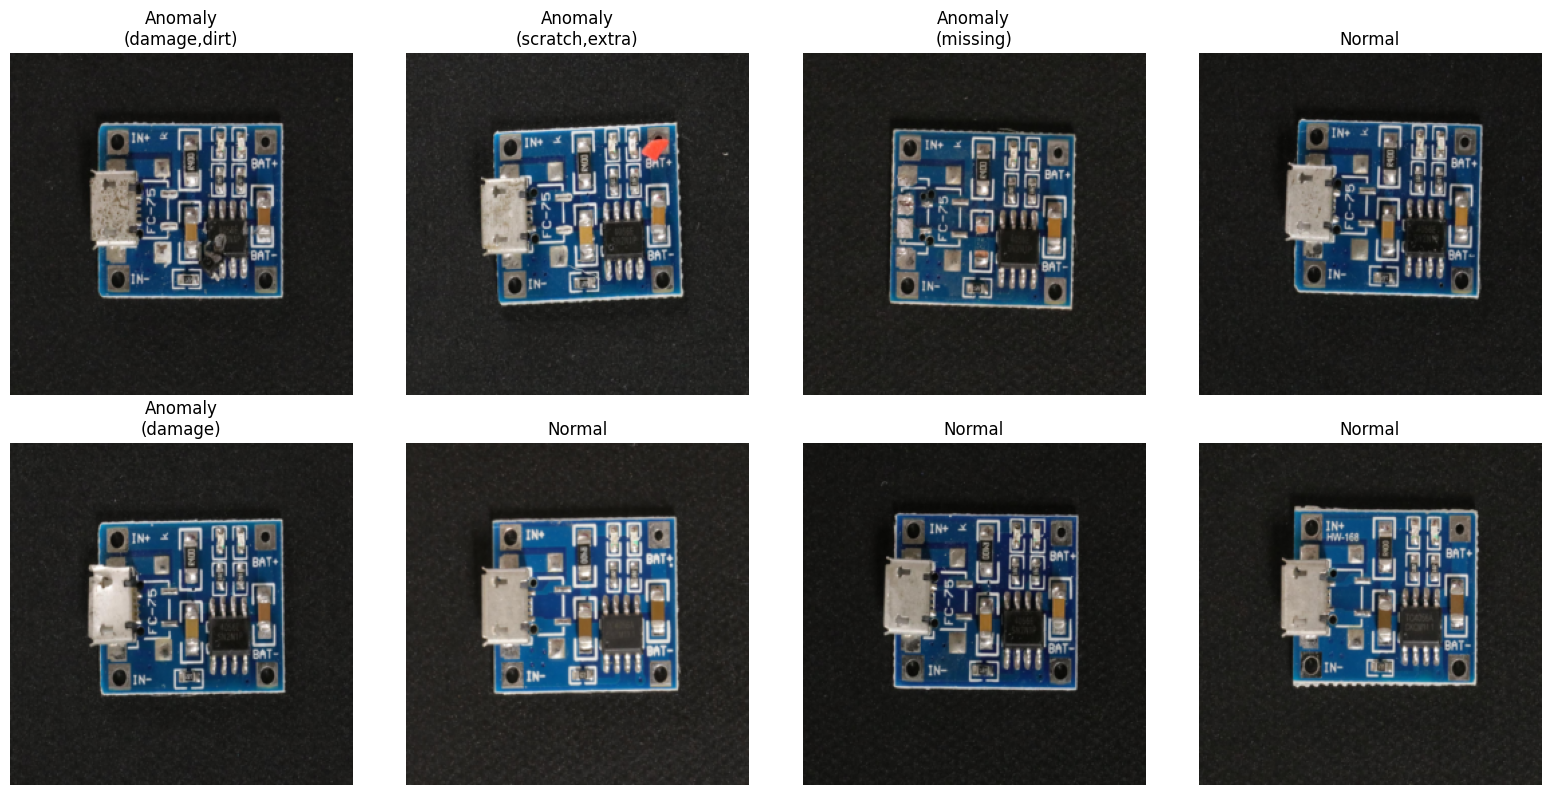

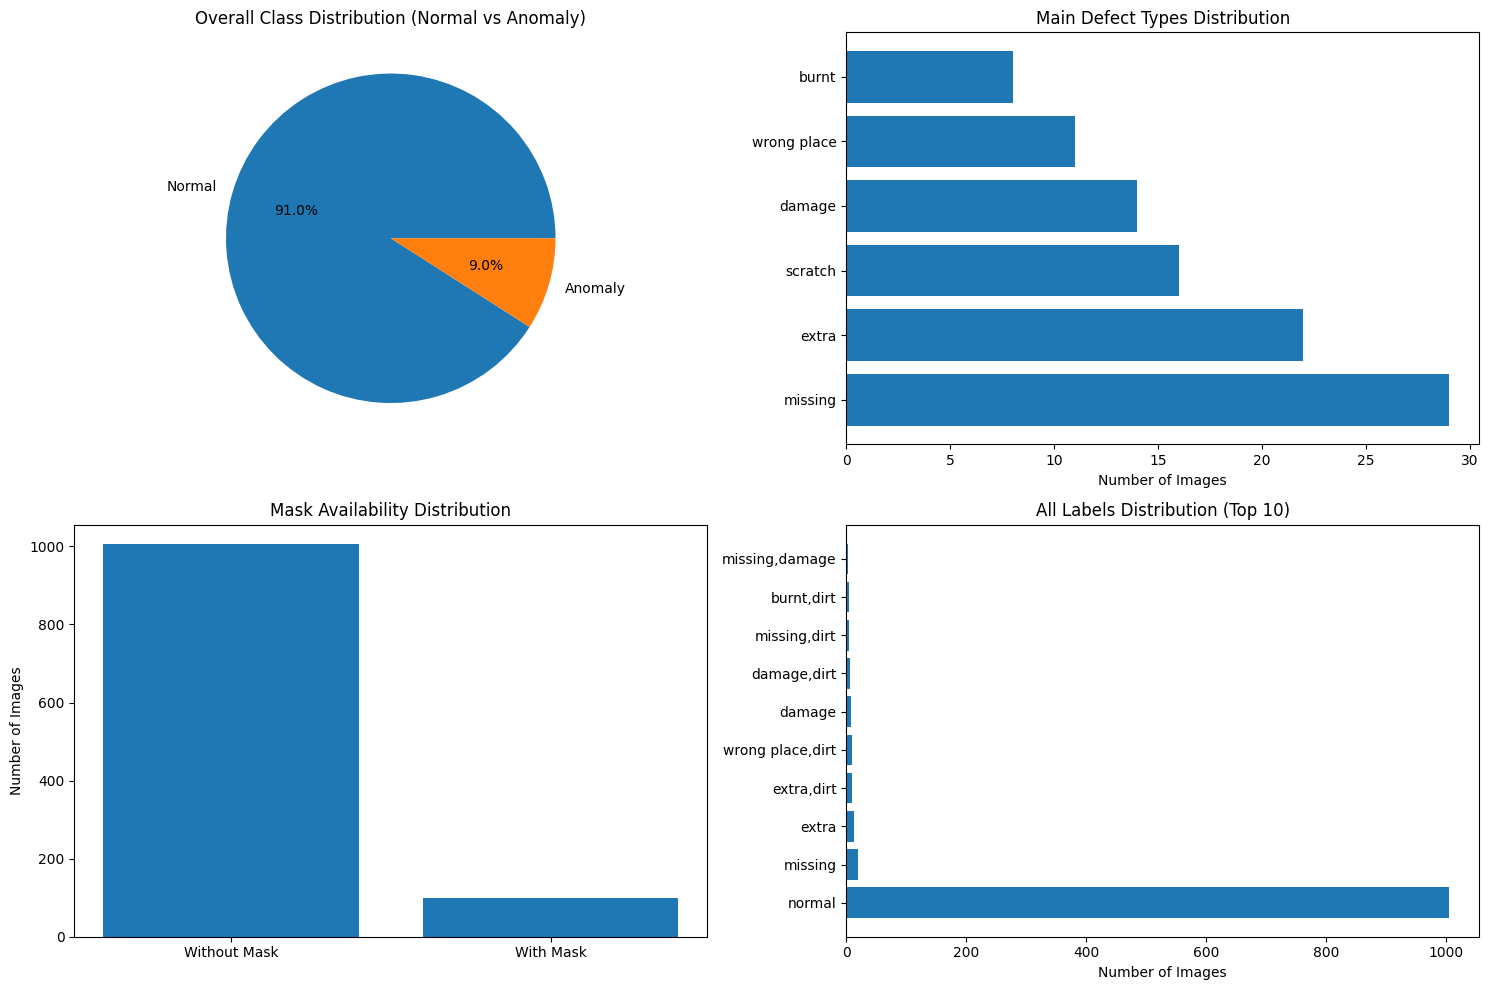

Total images: 1105
Normal images: 1005
Anomaly images: 100
Images with masks: 100
Unique defect types: 27


In [27]:
visualize_visa_samples(test_loader.dataset)
plot_visa_statistics(DATA_PATH, CATEGORY_NAME)

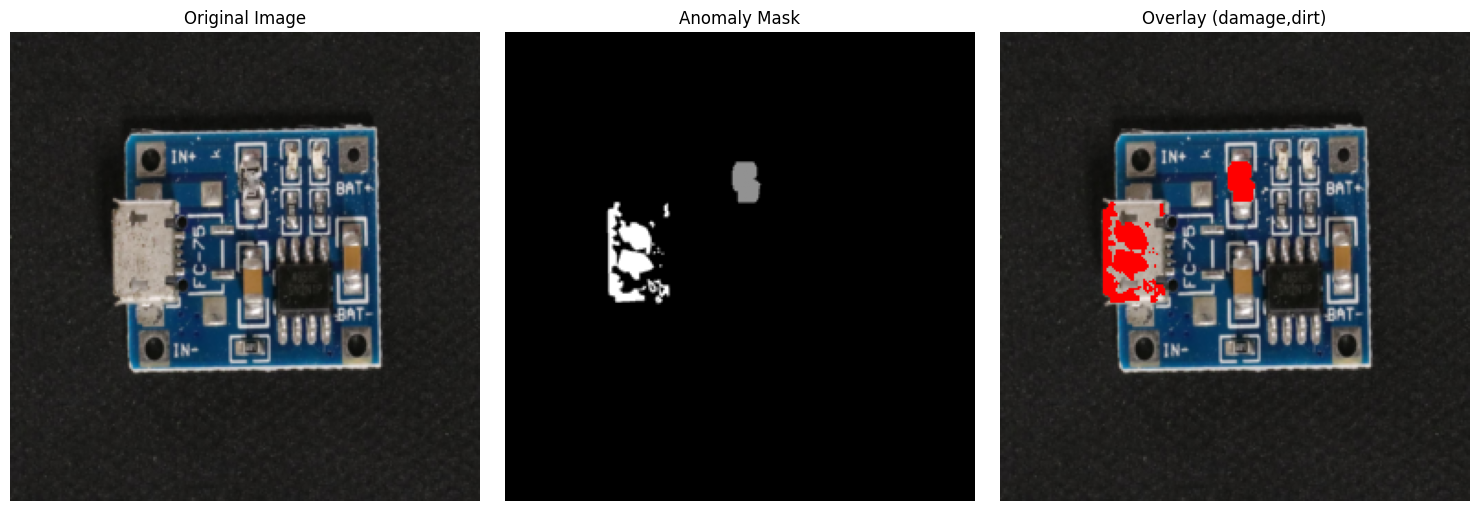

In [28]:
visualize_with_mask(test_loader.dataset, 210)

## 모델 구현

In [29]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
import torchvision.transforms as transforms
import torchvision.models as models

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_auc_score, precision_recall_curve, auc, roc_curve
from sklearn.manifold import TSNE
from sklearn.decomposition import PCA
from sklearn.svm import OneClassSVM
from sklearn.preprocessing import StandardScaler

import cv2
from PIL import Image
from pathlib import Path
import pickle
import json
from tqdm import tqdm
import warnings
warnings.filterwarnings('ignore')

# GPU 설정
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"사용 장치: {device}")


사용 장치: cuda


In [30]:
class FeatureExtractor(nn.Module):
    def __init__(self, model_name='resnet18', layers_to_extract=['layer1', 'layer2', 'layer3']):
        super(FeatureExtractor, self).__init__()

        if model_name == 'resnet18':
            self.model = models.resnet18(pretrained=True)
        elif model_name == 'resnet50':
            self.model = models.resnet50(pretrained=True)
        elif model_name == 'wide_resnet50':
            self.model = models.wide_resnet50_2(pretrained=True)
        else:
            raise ValueError(f"지원하지 않는 모델: {model_name}")

        self.layers_to_extract = layers_to_extract
        self.features = {}

        # Hook 등록
        for name, module in self.model.named_modules():
            if name in layers_to_extract:
                # 지정한 중간 레이어의 출력을 저장해 특징맵으로 사용한다.
                # 최종 분류 결과 대신 중간 표현을 이상 탐지에 활용한다.
                module.register_forward_hook(self.save_features(name))

        # 평가 모드로 설정
        # BatchNorm 등을 평가 시 동작으로 설정한다.
        self.model.eval()

        # 그래디언트 계산 비활성화
        # CNN 가중치는 고정하고, 정상 이미지에서 특징만 추출한다.
        for param in self.model.parameters():
            param.requires_grad = False

    def save_features(self, name):
        def hook(module, input, output):
            self.features[name] = output
        return hook

    def forward(self, x):
        self.features.clear()
        _ = self.model(x)
        return self.features

# Feature Extractor 초기화
feature_extractor = FeatureExtractor('wide_resnet50', ['layer2', 'layer3']).to(device)

Downloading: "https://download.pytorch.org/models/wide_resnet50_2-95faca4d.pth" to /root/.cache/torch/hub/checkpoints/wide_resnet50_2-95faca4d.pth


100%|██████████| 132M/132M [00:00<00:00, 241MB/s] 


이 코드의 PaDiM과 One-Class SVM은 사전학습된 CNN을 특징 추출기로 사용한다. CNN 가중치를 다시 학습하지 않으며, 추출한 정상 특징을 이용해 통계나 정상 영역의 경계를 학습한다. eval()과 기울기 계산 비활성화는 서로 다른 역할이라는 점을 구분했다.

In [31]:
class PaDiM:
    def __init__(self, feature_extractor, d_reduced=100):
        self.feature_extractor = feature_extractor
        self.d_reduced = d_reduced
        self.means = []
        self.inv_covariances = []
        self.projection_matrix = None

    def fit(self, train_loader):
        """정상 데이터로 모델 훈련"""
        print("PaDiM 훈련 시작...")

        # 모든 훈련 데이터에서 특징 추출
        all_features = []

        for batch in tqdm(train_loader, desc="특징 추출 중"):
            images = batch['image'].to(device)

            with torch.no_grad():
                features = self.feature_extractor(images)

                # 각 이미지별로 처리
                for i in range(images.size(0)):
                    img_features = []

                    # 레이어별 특징 추출 및 결합
                    for layer_name, feat in features.items():
                        # 단일 이미지 특징 추출
                        single_feat = feat[i:i+1]  # [1, C, H, W]

                        # 28x28로 리사이즈
                        # 입력 특징맵 [1, C, H, W]의 공간 크기를 28×28로 맞춘다.
                        feat_resized = F.adaptive_avg_pool2d(single_feat, (28, 28))

                        # [1, C, 28, 28] → [1, 28, 28, C] → [784, C]
                        # 한 행이 하나의 공간 위치에 대한 특징 벡터가 된다.
                        feat_patches = feat_resized.permute(0, 2, 3, 1).reshape(28*28, -1)
                        img_features.append(feat_patches)

                    # 레이어별 특징 결합 [784, total_channels]
                    # 동일한 위치의 여러 레이어 특징을 채널 방향으로 이어 붙인다.
                    # 결과 크기: [784, 여러 레이어의 채널 수 합]
                    combined_features = torch.cat(img_features, dim=1)
                    # 정상 이미지 N장의 특징을 모은다.
                    # 결과 크기: [N × 784, 전체 특징 차원]
                    all_features.append(combined_features)

        # 모든 특징을 하나로 결합 [N*784, total_channels]
        all_features = torch.cat(all_features, dim=0)
        print(f"전체 특징 크기: {all_features.shape}")

        # 차원 축소를 위한 Random Projection 행렬 생성
        if all_features.shape[1] > self.d_reduced:
            # 이 구현은 무작위 투영 행렬로 특징 차원을 줄인다.
            # 결과의 재현성을 확인하려면 난수 시드도 관리해야 한다.
            self.projection_matrix = torch.randn(all_features.shape[1], self.d_reduced).to(device)
            # 정규화
            self.projection_matrix = F.normalize(self.projection_matrix, dim=0)

            # 차원 축소 적용
            all_features = torch.mm(all_features, self.projection_matrix)
            print(f"차원 축소 후 크기: {all_features.shape}")

        # 패치 위치별로 분리하여 통계 계산
        n_samples = len(all_features) // (28 * 28)

        for patch_idx in range(28 * 28):
            # 특정 패치 위치의 모든 특징 추출
            # 이미지마다 784개 위치가 순서대로 저장되어 있다.
            # 784칸 간격으로 선택하면 서로 다른 이미지의 동일 위치 특징을 모을 수 있다.
            patch_features = all_features[patch_idx::28*28]  # [n_samples, d_reduced]

            # 평균과 공분산 계산
            mean = torch.mean(patch_features, dim=0)

            # 공분산 행렬 계산 (정규화 추가)
            centered_features = patch_features - mean
            cov = torch.mm(centered_features.T, centered_features) / (patch_features.shape[0] - 1)

            # 수치 안정성을 위한 정규화
            # 공분산의 대각 성분에 작은 값을 더해 역행렬 계산을 안정화한다.
            cov += torch.eye(cov.shape[0]).to(device) * 1e-4

            # 역행렬 계산
            try:
                inv_cov = torch.linalg.inv(cov)
            except:
                # 특이행렬인 경우 pseudo-inverse 사용
                inv_cov = torch.linalg.pinv(cov)

            self.means.append(mean)
            self.inv_covariances.append(inv_cov)

        print(f"PaDiM 훈련 완료! (패치 수: {len(self.means)})")

    def predict(self, test_loader):
        """테스트 데이터에 대한 이상 점수 계산"""
        anomaly_scores = []

        for batch in tqdm(test_loader, desc="이상 탐지 중"):
            images = batch['image'].to(device)

            with torch.no_grad():
                features = self.feature_extractor(images)

                # 각 이미지별로 처리
                for i in range(images.size(0)):
                    img_features = []

                    # 레이어별 특징 추출 및 결합
                    for layer_name, feat in features.items():
                        single_feat = feat[i:i+1]
                        feat_resized = F.adaptive_avg_pool2d(single_feat, (28, 28))
                        feat_patches = feat_resized.permute(0, 2, 3, 1).reshape(28*28, -1)
                        img_features.append(feat_patches)

                    combined_features = torch.cat(img_features, dim=1)

                    # 차원 축소 (훈련 시와 동일한 방식)
                    if self.projection_matrix is not None:
                        combined_features = torch.mm(combined_features, self.projection_matrix)

                    # 각 패치별 Mahalanobis 거리 계산
                    patch_scores = []
                    for patch_idx in range(28 * 28):
                        diff = combined_features[patch_idx] - self.means[patch_idx]

                        # Mahalanobis 거리 계산
                        mahal_dist = torch.sqrt(torch.mm(
                            torch.mm(diff.unsqueeze(0), self.inv_covariances[patch_idx]),
                            diff.unsqueeze(1)
                        )).item()

                        patch_scores.append(mahal_dist)

                    # 전체 이상 점수 (최대값 사용)
                    # 가장 이상한 위치의 점수를 이미지 전체 점수로 사용한다.
                    # 작은 결함에도 반응할 수 있지만, 한 위치의 잡음에도 민감할 수 있다.
                    anomaly_scores.append(max(patch_scores))

        return np.array(anomaly_scores), None

28×28은 특징맵의 공간 해상도이며, 총 784개 위치에서 특징을 비교한다. 각 위치마다 정상 이미지들의 특징을 모아 별도의 평균과 공분산을 계산한다. 따라서 모든 위치를 하나의 정상 분포로 처리하는 방식과는 차이가 있다.

In [32]:
class ConvAutoEncoder(nn.Module):
    def __init__(self, input_channels=3, latent_dim=128):
        super(ConvAutoEncoder, self).__init__()

        # Encoder
        self.encoder = nn.Sequential(
            nn.Conv2d(input_channels, 32, 4, stride=2, padding=1),  # 128x128
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.Conv2d(32, 64, 4, stride=2, padding=1),  # 64x64
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.Conv2d(64, 128, 4, stride=2, padding=1),  # 32x32
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.Conv2d(128, 256, 4, stride=2, padding=1),  # 16x16
            nn.BatchNorm2d(256),
            nn.ReLU(),
            nn.Conv2d(256, latent_dim, 4, stride=2, padding=1),  # 8x8
            nn.BatchNorm2d(latent_dim),
            nn.ReLU()
        )

        # Decoder
        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(latent_dim, 256, 4, stride=2, padding=1),  # 16x16
            nn.BatchNorm2d(256),
            nn.ReLU(),
            nn.ConvTranspose2d(256, 128, 4, stride=2, padding=1),  # 32x32
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.ConvTranspose2d(128, 64, 4, stride=2, padding=1),  # 64x64
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.ConvTranspose2d(64, 32, 4, stride=2, padding=1),  # 128x128
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.ConvTranspose2d(32, input_channels, 4, stride=2, padding=1),  # 256x256
            nn.Sigmoid()
        )

    def forward(self, x):
        encoded = self.encoder(x)
        decoded = self.decoder(encoded)
        return decoded

class AutoEncoderAnomalyDetector:
    def __init__(self, input_size=(256, 256), latent_dim=128):
        self.model = ConvAutoEncoder(input_channels=3, latent_dim=latent_dim).to(device)
        self.criterion = nn.MSELoss()
        self.optimizer = torch.optim.Adam(self.model.parameters(), lr=0.001)
        self.input_size = input_size

    def fit(self, train_loader, epochs=50):
        """AutoEncoder 훈련"""
        print("AutoEncoder 훈련 시작...")
        self.model.train()

        train_losses = []

        for epoch in range(epochs):
            epoch_loss = 0
            for batch in tqdm(train_loader, desc=f"Epoch {epoch+1}/{epochs}"):
                images = batch['image'].to(device)

                self.optimizer.zero_grad()
                reconstructed = self.model(images)
                # 별도의 클래스 정답 대신 입력 이미지 자체를 복원 목표로 사용한다.
                # 정상 이미지의 재구성 오차가 줄어들도록 학습한다.
                loss = self.criterion(reconstructed, images)
                loss.backward()
                self.optimizer.step()

                epoch_loss += loss.item()

            avg_loss = epoch_loss / len(train_loader)
            train_losses.append(avg_loss)
            print(f"Epoch {epoch+1}, Loss: {avg_loss:.6f}")

        self.model.eval()
        print("AutoEncoder 훈련 완료!")
        return train_losses

    def predict(self, test_loader):
        """테스트 데이터에 대한 재구성 오차 계산"""
        self.model.eval()
        anomaly_scores = []

        with torch.no_grad():
            for batch in tqdm(test_loader, desc="이상 탐지 중"):
                images = batch['image'].to(device)
                reconstructed = self.model(images)

                # 픽셀별 재구성 오차
                reconstruction_errors = F.mse_loss(reconstructed, images, reduction='none')
                # 모든 채널과 픽셀의 오차를 평균해 이미지당 하나의 이상 점수를 만든다.
                # 결함이 아주 작으면 전체 평균에서 결함의 영향이 작아질 수 있다.
                reconstruction_errors = reconstruction_errors.view(images.size(0), -1).mean(dim=1)

                anomaly_scores.extend(reconstruction_errors.cpu().numpy())

        return np.array(anomaly_scores)

입력 전처리에는 Normalize가 포함되어 있어 값이 0~1 범위를 벗어날 수 있지만, 디코더 마지막 Sigmoid의 출력은 0~1로 제한된다. 이 경우 입력을 그대로 복원하기 어려운 값이 생긴다. AutoEncoder용 입력을 0~1 범위로 구성하거나 마지막 출력층을 바꾸는 등 입력과 출력의 범위를 맞추는 방법을 검토해야 한다.

In [33]:
class OneClassSVMAnomalyDetector:
    def __init__(self, feature_extractor, nu=0.1):
        self.feature_extractor = feature_extractor
        self.svm = OneClassSVM(nu=nu, kernel='rbf', gamma='scale')
        self.scaler = StandardScaler()

    def extract_features(self, data_loader):
        """특징 추출"""
        features = []

        for batch in tqdm(data_loader, desc="특징 추출 중"):
            images = batch['image'].to(device)

            with torch.no_grad():
                feat_dict = self.feature_extractor(images)

                # 모든 레이어의 특징을 결합하고 평균 풀링
                combined_features = []
                for layer_name, feat in feat_dict.items():
                    pooled_feat = F.adaptive_avg_pool2d(feat, (1, 1))
                    # 각 채널의 공간 정보를 평균해 이미지 전체를 대표하는 특징으로 압축한다.
                    # PaDiM과 달리 위치별 특징을 그대로 유지하지 않는다.
                    combined_features.append(pooled_feat.view(feat.size(0), -1))

                batch_features = torch.cat(combined_features, dim=1)
                features.append(batch_features.cpu().numpy())

        return np.concatenate(features, axis=0)

    def fit(self, train_loader):
        """One-Class SVM 훈련"""
        print("One-Class SVM 훈련 시작...")

        # 특징 추출
        train_features = self.extract_features(train_loader)

        # 정규화
        # 평균과 표준편차는 학습 데이터에서만 추정한다.
        train_features_scaled = self.scaler.fit_transform(train_features)

        # SVM 훈련
        self.svm.fit(train_features_scaled)
        print("One-Class SVM 훈련 완료!")

    def predict(self, test_loader):
        """테스트 데이터에 대한 이상 점수 계산"""
        # 특징 추출
        test_features = self.extract_features(test_loader)

        # 정규화
        # 테스트에는 학습 때 구한 동일한 변환을 적용한다.
        test_features_scaled = self.scaler.transform(test_features)

        # 이상 점수 계산 (결정 함수의 음수)
        # 값이 클수록 이상이라는 방향으로 다른 모델과 점수 방향을 맞춘다.
        anomaly_scores = -self.svm.decision_function(test_features_scaled)

        return anomaly_scores

In [34]:
class AnomalyDetectionEvaluator:
    def __init__(self):
        self.results = {}

    def evaluate(self, y_true, y_scores, method_name):
        """평가 메트릭 계산"""
        # AUROC
        auroc = roc_auc_score(y_true, y_scores)

        # AUPRC
        precision, recall, thresholds = precision_recall_curve(y_true, y_scores)
        auprc = auc(recall, precision)

        # 최적 임계값에서의 F1 스코어
        f1_scores = 2 * (precision * recall) / (precision + recall + 1e-8)

        # NaN 값 제거
        valid_indices = ~np.isnan(f1_scores)
        if np.any(valid_indices):
            valid_f1_scores = f1_scores[valid_indices]
            valid_thresholds = thresholds[valid_indices] if len(thresholds) == len(f1_scores) else thresholds[:len(valid_f1_scores)]

            # 현재 평가 데이터에서 F1이 가장 높은 임계값을 선택한다.
            # 실제 성능 검증에서는 별도 검증 데이터로 임계값을 정하는 것이 필요하다.
            best_f1_idx = np.argmax(valid_f1_scores)
            best_f1 = valid_f1_scores[best_f1_idx]
            best_threshold = valid_thresholds[best_f1_idx] if len(valid_thresholds) > best_f1_idx else 0.5
        else:
            best_f1 = 0.0
            best_threshold = 0.5

        self.results[method_name] = {
            'AUROC': auroc,
            'AUPRC': auprc,
            'Best_F1': best_f1,
            'Best_Threshold': best_threshold,
            'y_true': y_true,
            'y_scores': y_scores
        }

        print(f"{method_name} 결과:")
        print(f"  AUROC: {auroc:.4f}")
        print(f"  AUPRC: {auprc:.4f}")
        print(f"  Best F1: {best_f1:.4f}")
        print()

        return auroc, auprc, best_f1

    def plot_roc_curve(self):
        """ROC 곡선 그리기"""
        plt.figure(figsize=(10, 8))

        for method_name, result in self.results.items():
            fpr, tpr, _ = roc_curve(result['y_true'], result['y_scores'])
            plt.plot(fpr, tpr, label=f"{method_name} (AUC = {result['AUROC']:.3f})")

        plt.plot([0, 1], [0, 1], 'k--', label='Random')
        plt.xlabel('False Positive Rate')
        plt.ylabel('True Positive Rate')
        plt.title('ROC Curves Comparison')
        plt.legend()
        plt.grid(True)
        plt.show()

    def plot_precision_recall_curve(self):
        """PR 곡선 그리기"""
        plt.figure(figsize=(10, 8))

        for method_name, result in self.results.items():
            precision, recall, _ = precision_recall_curve(result['y_true'], result['y_scores'])
            plt.plot(recall, precision, label=f"{method_name} (AUC = {result['AUPRC']:.3f})")

        plt.xlabel('Recall')
        plt.ylabel('Precision')
        plt.title('Precision-Recall Curves Comparison')
        plt.legend()
        plt.grid(True)
        plt.show()

    def plot_score_distribution(self):
        """이상 점수 분포 시각화"""
        fig, axes = plt.subplots(len(self.results), 1, figsize=(12, 4*len(self.results)))
        if len(self.results) == 1:
            axes = [axes]

        for i, (method_name, result) in enumerate(self.results.items()):
            normal_scores = result['y_scores'][result['y_true'] == 0]
            anomaly_scores = result['y_scores'][result['y_true'] == 1]

            axes[i].hist(normal_scores, bins=50, alpha=0.7, label='Normal', density=True)
            axes[i].hist(anomaly_scores, bins=50, alpha=0.7, label='Anomaly', density=True)
            axes[i].axvline(result['Best_Threshold'], color='red', linestyle='--',
                           label=f"Best Threshold: {result['Best_Threshold']:.3f}")
            axes[i].set_title(f'{method_name} - Anomaly Score Distribution')
            axes[i].set_xlabel('Anomaly Score')
            axes[i].set_ylabel('Density')
            axes[i].legend()
            axes[i].grid(True)

        plt.tight_layout()
        plt.show()

    def compare_methods(self):
        """방법별 성능 비교"""
        methods = list(self.results.keys())
        aurocs = [self.results[m]['AUROC'] for m in methods]
        auprcs = [self.results[m]['AUPRC'] for m in methods]
        f1_scores = [self.results[m]['Best_F1'] for m in methods]

        x = np.arange(len(methods))
        width = 0.25

        plt.figure(figsize=(12, 6))
        plt.bar(x - width, aurocs, width, label='AUROC', alpha=0.8)
        plt.bar(x, auprcs, width, label='AUPRC', alpha=0.8)
        plt.bar(x + width, f1_scores, width, label='Best F1', alpha=0.8)

        plt.xlabel('Methods')
        plt.ylabel('Score')
        plt.title('Performance Comparison')
        plt.xticks(x, methods, rotation=45)
        plt.legend()
        plt.grid(True, alpha=0.3)
        plt.tight_layout()
        plt.show()

In [35]:
class VisAAnomalyDetectionSystem:
    def __init__(self, data_path, category):
        self.data_path = data_path
        self.category = category
        self.evaluator = AnomalyDetectionEvaluator()

        # 데이터 로더 생성
        self.train_loader, self.test_loader = create_visa_data_loaders(
            data_path, category, batch_size=16, include_mask=False, train_ratio=0.8
        )

        # 테스트 레이블 추출
        self.test_labels = []
        for batch in self.test_loader:
            self.test_labels.extend(batch['label'].numpy())
        self.test_labels = np.array(self.test_labels)

        print(f"시스템 초기화 완료:")
        print(f"  카테고리: {category}")
        print(f"  훈련 데이터: {len(self.train_loader.dataset)}개")
        print(f"  테스트 데이터: {len(self.test_loader.dataset)}개")
        print(f"  테스트 중 이상 데이터: {self.test_labels.sum()}개")

    def run_padim(self):
        """PaDiM 실행"""
        print("\n=== PaDiM 실행 ===")
        padim = PaDiM(feature_extractor, d_reduced=100)
        padim.fit(self.train_loader)
        scores, _ = padim.predict(self.test_loader)
        self.evaluator.evaluate(self.test_labels, scores, 'PaDiM')
        return scores

    def run_autoencoder(self, epochs=30):
        """AutoEncoder 실행"""
        print("\n=== AutoEncoder 실행 ===")
        ae_detector = AutoEncoderAnomalyDetector()
        ae_detector.fit(self.train_loader, epochs=epochs)
        scores = ae_detector.predict(self.test_loader)
        self.evaluator.evaluate(self.test_labels, scores, 'AutoEncoder')
        return scores

    def run_ocsvm(self):
        """One-Class SVM 실행"""
        print("\n=== One-Class SVM 실행 ===")
        ocsvm_detector = OneClassSVMAnomalyDetector(feature_extractor, nu=0.1)
        ocsvm_detector.fit(self.train_loader)
        scores = ocsvm_detector.predict(self.test_loader)
        self.evaluator.evaluate(self.test_labels, scores, 'One-Class SVM')
        return scores

    def run_all_methods(self):
        """모든 방법 실행 및 비교"""
        print("모든 anomaly detection 방법을 실행합니다...")

        # 각 방법 실행 (오류가 발생해도 계속 진행)
        methods_tried = []

        # 1. AutoEncoder (가장 안정적)
        try:
            print("\n=== AutoEncoder 실행 ===")
            self.run_autoencoder(epochs=15)
            methods_tried.append("AutoEncoder")
        except Exception as e:
            print(f"AutoEncoder 실행 중 오류: {e}")

        # 2. One-Class SVM
        try:
            print("\n=== One-Class SVM 실행 ===")
            self.run_ocsvm()
            methods_tried.append("One-Class SVM")
        except Exception as e:
            print(f"One-Class SVM 실행 중 오류: {e}")

        # 3. PaDiM (메모리 사용량이 많을 수 있음)
        try:
            print("\n=== PaDiM 실행 ===")
            self.run_padim()
            methods_tried.append("PaDiM")
        except Exception as e:
            print(f"PaDiM 실행 중 오류: {e}")
            print("팁: GPU 메모리가 부족할 수 있습니다. 배치 크기를 줄여보세요.")

        # 결과 시각화
        if self.evaluator.results:
            print(f"\n=== 전체 결과 ({len(methods_tried)}개 방법 성공) ===")
            try:
                self.evaluator.compare_methods()
            except Exception as e:
                print(f"비교 차트 생성 중 오류: {e}")

            try:
                self.evaluator.plot_roc_curve()
            except Exception as e:
                print(f"ROC 곡선 생성 중 오류: {e}")

            try:
                self.evaluator.plot_precision_recall_curve()
            except Exception as e:
                print(f"PR 곡선 생성 중 오류: {e}")

            try:
                self.evaluator.plot_score_distribution()
            except Exception as e:
                print(f"점수 분포 차트 생성 중 오류: {e}")
        else:
            print("❌ 성공적으로 실행된 방법이 없습니다.")
            print("다음을 확인해보세요:")
            print("1. 데이터 경로가 올바른지 확인")
            print("2. GPU 메모리가 충분한지 확인")
            print("3. 필요한 라이브러리가 모두 설치되어 있는지 확인")

    def save_results(self, filename):
        """결과 저장"""
        results_to_save = {}
        for method, result in self.evaluator.results.items():
            results_to_save[method] = {
                'AUROC': result['AUROC'],
                'AUPRC': result['AUPRC'],
                'Best_F1': result['Best_F1'],
                'Best_Threshold': result['Best_Threshold']
            }

        with open(filename, 'w') as f:
            json.dump(results_to_save, f, indent=2)
        print(f"결과가 {filename}에 저장되었습니다.")

In [36]:
system = VisAAnomalyDetectionSystem("./VisA", "pcb4")

# 개별 방법 실행
padim_scores = system.run_padim()
ae_scores = system.run_autoencoder(epochs=50)
svm_scores = system.run_ocsvm()


CSV 컬럼: ['image', 'label', 'mask']
훈련용 정상 데이터: 804개
CSV 컬럼: ['image', 'label', 'mask']
테스트용 정상 데이터: 201개
테스트용 비정상 데이터: 100개
시스템 초기화 완료:
  카테고리: pcb4
  훈련 데이터: 804개
  테스트 데이터: 301개
  테스트 중 이상 데이터: 100개

=== PaDiM 실행 ===
PaDiM 훈련 시작...


특징 추출 중: 100%|██████████| 51/51 [00:07<00:00,  6.91it/s]


전체 특징 크기: torch.Size([630336, 1536])
차원 축소 후 크기: torch.Size([630336, 100])
PaDiM 훈련 완료! (패치 수: 784)


이상 탐지 중: 100%|██████████| 19/19 [00:23<00:00,  1.22s/it]


PaDiM 결과:
  AUROC: 0.9461
  AUPRC: 0.8582
  Best F1: 0.8448


=== AutoEncoder 실행 ===
AutoEncoder 훈련 시작...


...

AutoEncoder 결과:
  AUROC: 0.2664
  AUPRC: 0.2263
  Best F1: 0.5249


=== One-Class SVM 실행 ===
One-Class SVM 훈련 시작...


특징 추출 중: 100%|██████████| 51/51 [00:07<00:00,  7.10it/s]


One-Class SVM 훈련 완료!


특징 추출 중: 100%|██████████| 19/19 [00:02<00:00,  6.45it/s]

One-Class SVM 결과:
  AUROC: 0.8193
  AUPRC: 0.7080
  Best F1: 0.6591



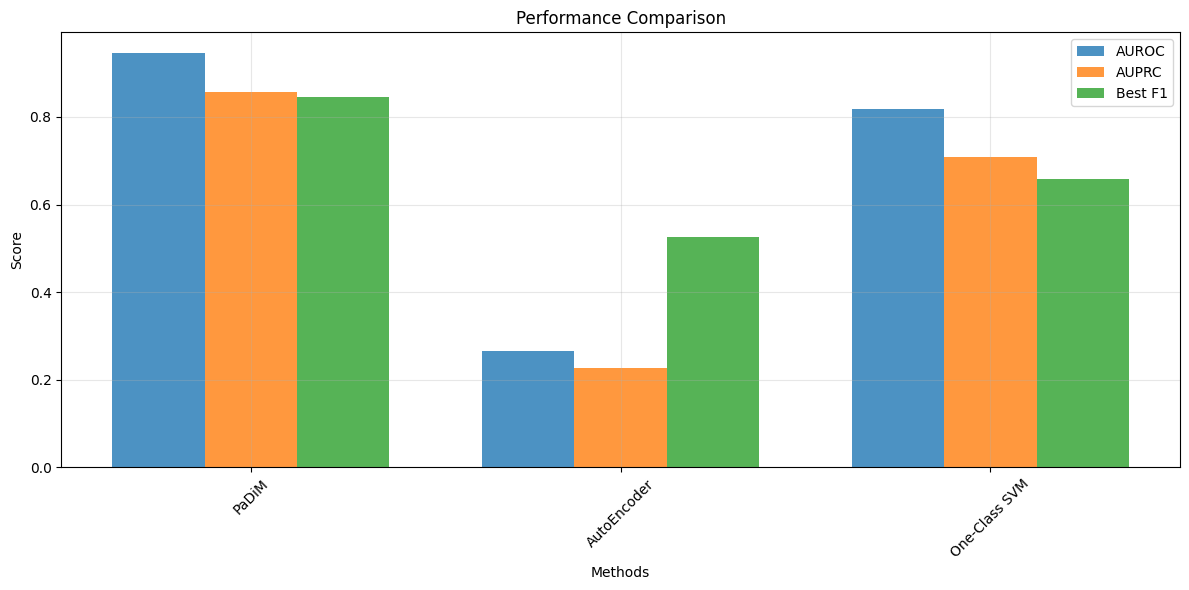

In [37]:
system.evaluator.compare_methods()

이번 실행에서 AUROC는 PaDiM이 0.9637로 가장 높았고, AUPRC도 PaDiM이 0.9045로 가장 높았다. 두 지표 모두 PaDiM, One-Class SVM, AutoEncoder 순으로 동일한 순위를 보였다. 이번 실험에서는 PaDiM이 정상과 비정상 이미지를 가장 잘 구분한 것으로 해석했다.

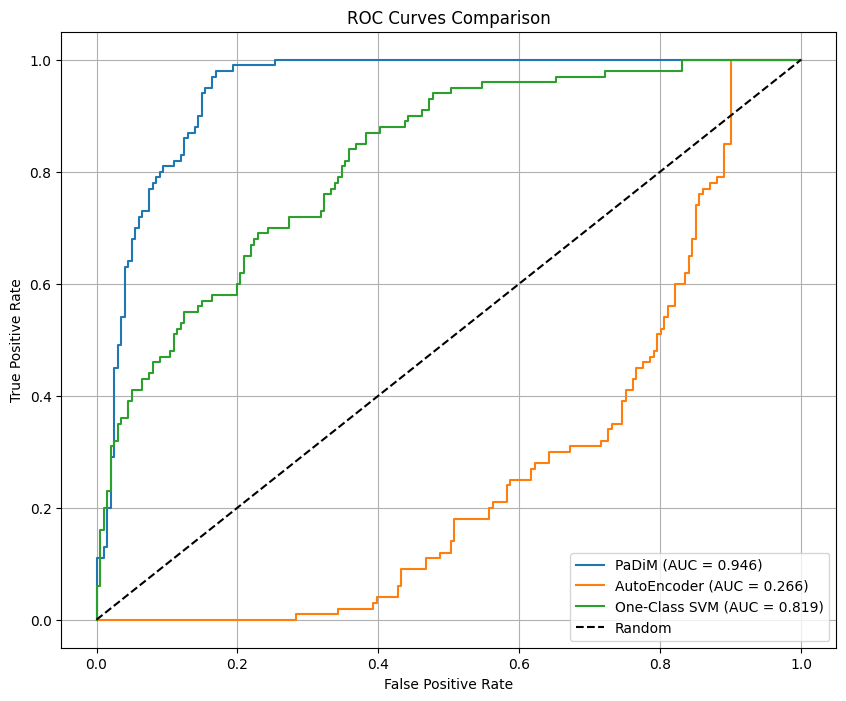

In [38]:
system.evaluator.plot_roc_curve()

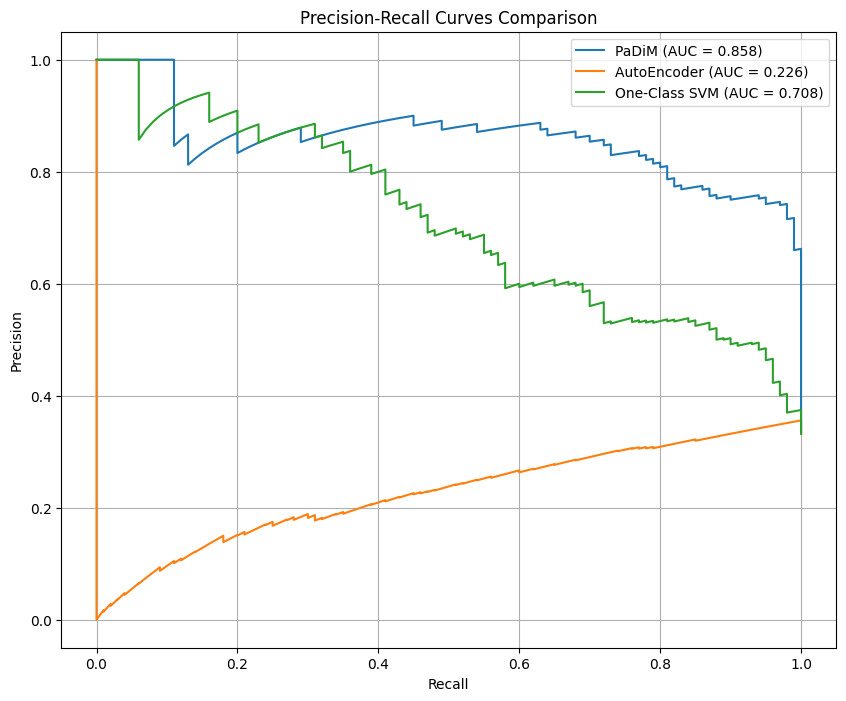

In [39]:
system.evaluator.plot_precision_recall_curve()

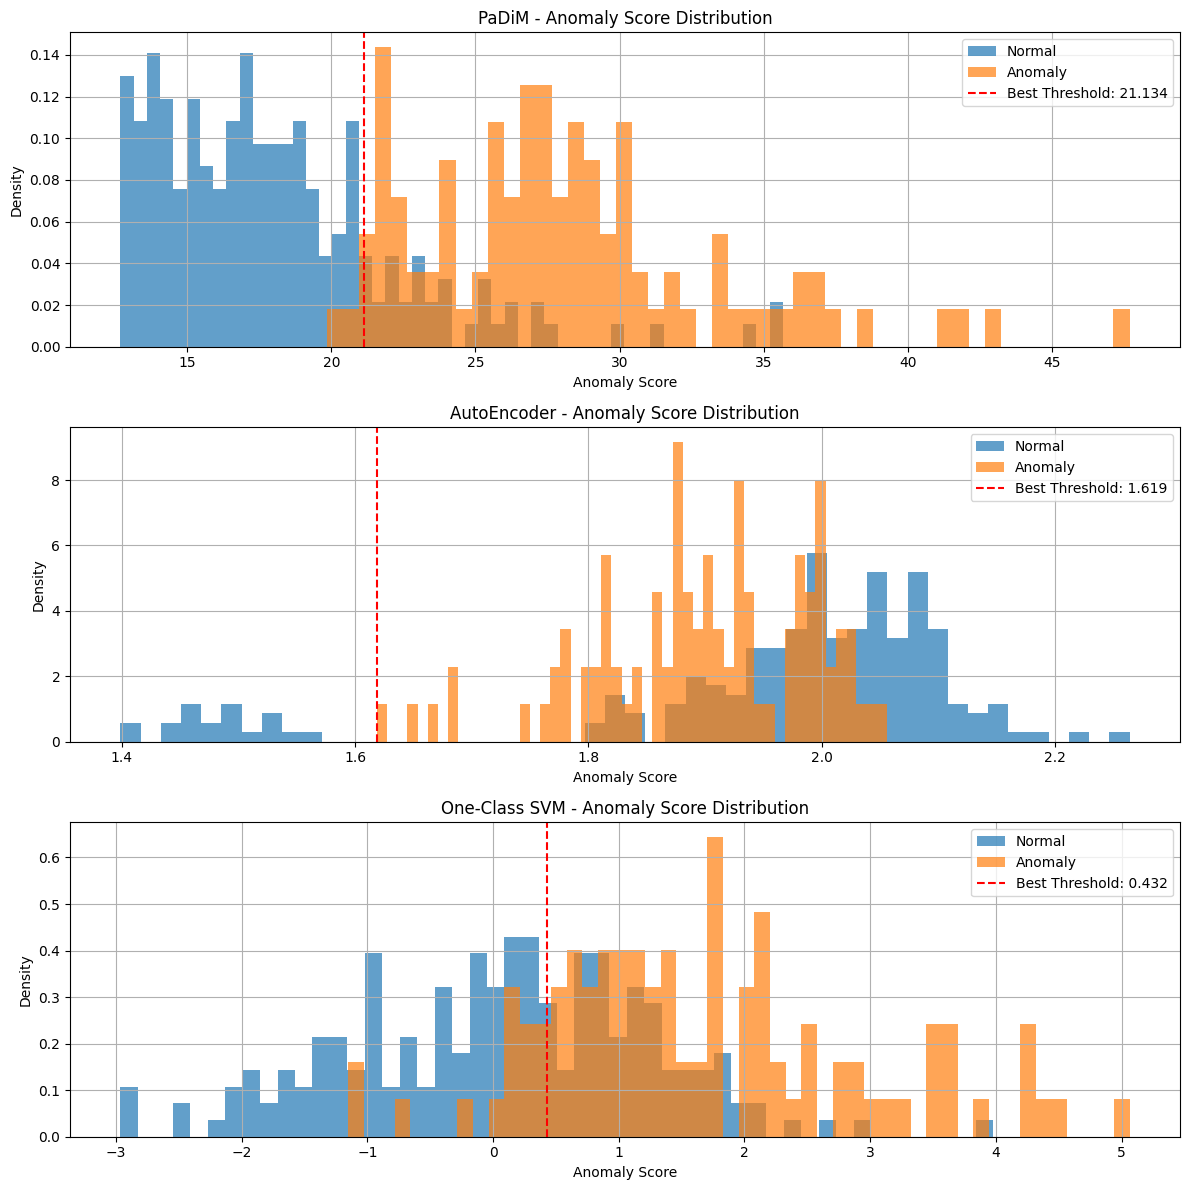

In [40]:
system.evaluator.plot_score_distribution()

AutoEncoder에서 정상과 비정상 점수 분포가 약 1.8~2.05 구간에서 상당히 겹쳤다. 특히 정상 이미지의 점수가 비정상 이미지보다 높은 쪽에 많이 분포해, ‘점수가 높을수록 이상’이라는 판정 방향과 반대되는 경향을 보였다. 이는 AUROC가 0.2661로 낮게 나온 결과와도 일치한다. 반면 PaDiM은 정상 점수가 낮은 쪽, 비정상 점수가 높은 쪽에 비교적 잘 분리되어 있었다. 모델마다 점수 계산 방식이 다르므로 점수의 절대 크기보다 정상과 비정상의 분리 정도를 비교해야 한다.

### 실시간 inference

아래에서는 앞에서 사용한 클래스와 함수를 다시 정의한다. 특히 PaDiM의 predict() 입력이 DataLoader에서 이미지 텐서로 바뀌므로 호출 방식에 주의해야 한다. 비교 실험 부분과 Gradio 부분은 각각 필요한 정의를 순서대로 실행해야 한다.

In [41]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.transforms as transforms
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import cv2
import numpy as np
import torchvision.models as models

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_auc_score, precision_recall_curve, auc, roc_curve
from sklearn.manifold import TSNE
from sklearn.decomposition import PCA
from sklearn.svm import OneClassSVM
from sklearn.preprocessing import StandardScaler

import cv2
from PIL import Image
from pathlib import Path
import pickle
import json
from tqdm import tqdm
import warnings

In [42]:
class VisADataset(Dataset):
    def __init__(self, data_path, category, transform=None, is_train=True, include_mask=False, train_ratio=0.8):
        self.data_path = Path(data_path)
        self.category = category
        self.transform = transform
        self.is_train = is_train
        self.include_mask = include_mask

        self.image_paths = []
        self.mask_paths = []
        self.labels = []
        self.defect_types = []

        category_path = self.data_path / category

        # CSV 파일에서 메타데이터 로드
        csv_path = category_path / "image_anno.csv"
        if csv_path.exists():
            df = pd.read_csv(csv_path)
            print(f"CSV 컬럼: {df.columns.tolist()}")

            # 정상/비정상 데이터 분리
            normal_df = df[df['label'] == 'normal'].copy()
            anomaly_df = df[df['label'] != 'normal'].copy()

            if self.is_train:
                # 훈련용: 정상 데이터의 일부만 사용
                train_size = int(len(normal_df) * train_ratio)
                selected_df = normal_df.iloc[:train_size]
                print(f"훈련용 정상 데이터: {len(selected_df)}개")
            else:
                # 테스트용: 나머지 정상 데이터 + 모든 비정상 데이터
                test_normal_size = len(normal_df) - int(len(normal_df) * train_ratio)
                test_normal_df = normal_df.iloc[-test_normal_size:] if test_normal_size > 0 else pd.DataFrame()
                selected_df = pd.concat([test_normal_df, anomaly_df], ignore_index=True)
                print(f"테스트용 정상 데이터: {len(test_normal_df)}개")
                print(f"테스트용 비정상 데이터: {len(anomaly_df)}개")

            # 데이터 로드
            for _, row in selected_df.iterrows():
                # 이미지 경로 처리 (중복 경로 제거)
                image_rel_path = row['image']
                if image_rel_path.startswith(category + '/'):
                    image_path = self.data_path / image_rel_path
                else:
                    image_path = category_path / image_rel_path

                if image_path.exists():
                    self.image_paths.append(str(image_path))
                    self.labels.append(0 if row['label'] == 'normal' else 1)
                    self.defect_types.append(row['label'])

                    # 마스크 경로 처리
                    if pd.notna(row['mask']) and self.include_mask:
                        mask_rel_path = row['mask']
                        if mask_rel_path.startswith(category + '/'):
                            mask_path = self.data_path / mask_rel_path
                        else:
                            mask_path = category_path / mask_rel_path
                        self.mask_paths.append(str(mask_path) if mask_path.exists() else None)
                    else:
                        self.mask_paths.append(None)
                else:
                    print(f"이미지 파일을 찾을 수 없습니다: {image_path}")
        else:
            print("CSV 파일이 없습니다. 폴더 구조를 기반으로 데이터를 로드합니다.")
            self._load_from_folder_structure()

    def _load_from_folder_structure(self):
        """폴더 구조를 기반으로 데이터 로드 (CSV가 없는 경우)"""
        category_path = self.data_path / self.category
        images_path = category_path / "Data" / "Images"
        masks_path = category_path / "Data" / "Masks"

        if self.is_train:
            # 훈련용: 정상 이미지만 사용
            normal_path = images_path / "Normal"
            if normal_path.exists():
                for img_path in normal_path.glob("*"):
                    if img_path.suffix.lower() in ['.jpg', '.jpeg', '.png', '.bmp']:
                        self.image_paths.append(str(img_path))
                        self.labels.append(0)  # 정상: 0
                        self.defect_types.append('normal')
                        self.mask_paths.append(None)
        else:
            # 테스트용: 정상 + 비정상 이미지
            # 정상 이미지
            normal_path = images_path / "Normal"
            if normal_path.exists():
                for img_path in normal_path.glob("*"):
                    if img_path.suffix.lower() in ['.jpg', '.jpeg', '.png', '.bmp']:
                        self.image_paths.append(str(img_path))
                        self.labels.append(0)
                        self.defect_types.append('normal')
                        self.mask_paths.append(None)

            # 비정상 이미지
            anomaly_path = images_path / "Anomaly"
            if anomaly_path.exists():
                for img_path in anomaly_path.glob("*"):
                    if img_path.suffix.lower() in ['.jpg', '.jpeg', '.png', '.bmp']:
                        self.image_paths.append(str(img_path))
                        self.labels.append(1)  # 이상: 1
                        self.defect_types.append('anomaly')

                        # 마스크 경로 찾기
                        if self.include_mask:
                            mask_name = img_path.stem + '.png'  # 확장자를 png로 변경
                            mask_path = masks_path / "Anomaly" / mask_name
                            self.mask_paths.append(str(mask_path) if mask_path.exists() else None)
                        else:
                            self.mask_paths.append(None)

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        # 이미지 로드
        image = Image.open(self.image_paths[idx]).convert('RGB')
        label = self.labels[idx]

        # 마스크 로드 (있는 경우)
        mask = None
        if self.include_mask and self.mask_paths[idx] is not None:
            try:
                mask = Image.open(self.mask_paths[idx]).convert('L')
            except:
                mask = None

        # 변환 적용
        if self.transform:
            image = self.transform(image)
            if mask is not None:
                mask_transform = transforms.Compose([
                    transforms.Resize((256, 256)),
                    transforms.ToTensor()
                ])
                mask = mask_transform(mask)

        result = {
            'image': image,
            'label': label,
            'defect_type': self.defect_types[idx]
        }

        if mask is not None:
            result['mask'] = mask

        return result

In [43]:
def create_visa_data_loaders(data_path, category, batch_size=32, include_mask=False, train_ratio=0.8):
    """
    VisA 데이터셋용 데이터 로더 생성

    Args:
        data_path: VisA 데이터셋 경로
        category: 카테고리 이름
        batch_size: 배치 크기
        include_mask: 마스크 포함 여부
        train_ratio: 훈련 데이터 비율 (정상 데이터에서)
    """
    train_transform, test_transform = get_visa_transforms()

    train_dataset = VisADataset(
        data_path, category,
        transform=train_transform,
        is_train=True,
        include_mask=include_mask,
        train_ratio=train_ratio
    )

    test_dataset = VisADataset(
        data_path, category,
        transform=test_transform,
        is_train=False,
        include_mask=include_mask,
        train_ratio=train_ratio
    )

    train_loader = DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True,
        num_workers=2,  # Windows에서 문제가 있을 수 있으므로 낮춤
        pin_memory=True
    )

    test_loader = DataLoader(
        test_dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=2,
        pin_memory=True
    )

    return train_loader, test_loader


In [44]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [45]:
class FeatureExtractor(nn.Module):
    def __init__(self, model_name='resnet18', layers_to_extract=['layer1', 'layer2', 'layer3']):
        super(FeatureExtractor, self).__init__()

        if model_name == 'resnet18':
            self.model = models.resnet18(pretrained=True)
        elif model_name == 'resnet50':
            self.model = models.resnet50(pretrained=True)
        elif model_name == 'wide_resnet50':
            self.model = models.wide_resnet50_2(pretrained=True)
        else:
            raise ValueError(f"지원하지 않는 모델: {model_name}")

        self.layers_to_extract = layers_to_extract
        self.features = {}

        # Hook 등록
        for name, module in self.model.named_modules():
            if name in layers_to_extract:
                module.register_forward_hook(self.save_features(name))

        # 평가 모드로 설정
        self.model.eval()

        # 그래디언트 계산 비활성화
        for param in self.model.parameters():
            param.requires_grad = False

    def save_features(self, name):
        def hook(module, input, output):
            self.features[name] = output
        return hook

    def forward(self, x):
        self.features.clear()
        _ = self.model(x)
        return self.features

# Feature Extractor 초기화
feature_extractor = FeatureExtractor('wide_resnet50', ['layer2', 'layer3']).to(device)


In [46]:
# --- PaDiM 클래스 (사용자 제공 코드, predict 수정) ---
class PaDiM:
    def __init__(self, feature_extractor, d_reduced=100, padim_patch_size=PADIM_PATCH_SIZE):
        self.feature_extractor = feature_extractor
        self.d_reduced = d_reduced
        self.padim_patch_size = padim_patch_size
        self.means = []
        self.inv_covariances = []
        self.projection_matrix = None

    def fit(self, train_loader):
        print("PaDiM 훈련 시작...")
        all_features = []
        for batch in tqdm(train_loader, desc="특징 추출 중"):
            images = batch['image'].to(device)
            with torch.no_grad():
                features = self.feature_extractor(images)
                for i in range(images.size(0)):
                    img_features = []
                    for layer_name, feat in features.items():
                        single_feat = feat[i:i+1]
                        feat_resized = F.adaptive_avg_pool2d(single_feat, (self.padim_patch_size, self.padim_patch_size))
                        feat_patches = feat_resized.permute(0, 2, 3, 1).reshape(self.padim_patch_size*self.padim_patch_size, -1)
                        img_features.append(feat_patches)
                    combined_features = torch.cat(img_features, dim=1)
                    all_features.append(combined_features)

        all_features = torch.cat(all_features, dim=0)
        print(f"전체 특징 크기: {all_features.shape}")

        if all_features.shape[1] > self.d_reduced:
            self.projection_matrix = torch.randn(all_features.shape[1], self.d_reduced).to(device)
            self.projection_matrix = F.normalize(self.projection_matrix, dim=0)
            all_features = torch.mm(all_features, self.projection_matrix)
            print(f"차원 축소 후 크기: {all_features.shape}")

        num_patches = self.padim_patch_size * self.padim_patch_size
        for patch_idx in range(num_patches):
            patch_features = all_features[patch_idx::num_patches]
            mean = torch.mean(patch_features, dim=0)
            centered_features = patch_features - mean
            cov = torch.mm(centered_features.T, centered_features) / (patch_features.shape[0] - 1)
            cov += torch.eye(cov.shape[0]).to(device) * 1e-4
            try:
                inv_cov = torch.linalg.inv(cov)
            except RuntimeError:
                inv_cov = torch.linalg.pinv(cov)
            self.means.append(mean)
            self.inv_covariances.append(inv_cov)
        print(f"PaDiM 훈련 완료! (패치 수: {len(self.means)})")

    def predict(self, images_tensor): # DataLoader 대신 이미지 텐서를 직접 받도록 수정
        """테스트 이미지 텐서에 대한 이상 점수 및 이상 맵 계산"""
        all_image_scores = []
        all_anomaly_maps = []

        with torch.no_grad():
            features = self.feature_extractor(images_tensor) # 이미지 텐서 바로 사용

            for i in range(images_tensor.size(0)):
                img_features = []
                for layer_name, feat in features.items():
                    single_feat = feat[i:i+1]
                    feat_resized = F.adaptive_avg_pool2d(single_feat, (self.padim_patch_size, self.padim_patch_size))
                    feat_patches = feat_resized.permute(0, 2, 3, 1).reshape(self.padim_patch_size*self.padim_patch_size, -1)
                    img_features.append(feat_patches)

                combined_features = torch.cat(img_features, dim=1)

                if self.projection_matrix is not None:
                    combined_features = torch.mm(combined_features, self.projection_matrix)

                patch_scores_for_image = []
                num_patches = self.padim_patch_size * self.padim_patch_size
                for patch_idx in range(num_patches):
                    diff = combined_features[patch_idx] - self.means[patch_idx]
                    mahal_dist = torch.sqrt(torch.mm(
                        torch.mm(diff.unsqueeze(0), self.inv_covariances[patch_idx]),
                        diff.unsqueeze(1)
                    )).item()
                    patch_scores_for_image.append(mahal_dist)

                all_image_scores.append(max(patch_scores_for_image))

                # 이상 맵 생성 (28x28 형태로)
                anomaly_map = torch.tensor(patch_scores_for_image).reshape(self.padim_patch_size, self.padim_patch_size).cpu().numpy()
                all_anomaly_maps.append(anomaly_map)

        return np.array(all_image_scores), np.array(all_anomaly_maps)

In [47]:
def get_visa_transforms():
    """
    VisA 데이터셋에 적용할 이미지 변환(transform)을 반환합니다.
    실제 데이터셋과 모델에 맞게 이 부분을 수정해야 합니다.
    """
    train_transform = transforms.Compose([
        transforms.Resize((IMG_SIZE, IMG_SIZE)),
        transforms.ToTensor(),
        transforms.Normalize(mean=NORMALIZE_MEAN, std=NORMALIZE_STD)
    ])

    # 테스트 시에는 일반적으로 Augmentation을 많이 하지 않습니다.
    test_transform = transforms.Compose([
        transforms.Resize((IMG_SIZE, IMG_SIZE)),
        transforms.ToTensor(),
        transforms.Normalize(mean=NORMALIZE_MEAN, std=NORMALIZE_STD)
    ])
    return train_transform, test_transform


앞부분과 달리 여기서는 학습 전처리에서도 좌우 반전을 사용하지 않는다. PaDiM이 같은 공간 위치의 특징을 비교한다는 점에서 제품 방향의 일관성이 어떤 영향을 주는지 생각해 볼 수 있다. 이후 새로 만드는 데이터 로더에는 이 전처리 정의가 사용된다.

In [48]:
# --- 데이터셋 경로 및 카테고리 설정 ---
# !!! 중요: 이 경로를 실제 VisA 데이터셋이 있는 경로로 수정해야 합니다 !!!
# 예시: DATA_PATH = "/path/to/your/visa_dataset"
# VisA 데이터셋이 없다면, 아래 예시처럼 직접 폴더를 만들고 소수의 이미지를 넣어 테스트할 수 있습니다.
# DATA_PATH/CATEGORY_NAME/train/good/img1.png, img2.png ...
# DATA_PATH/CATEGORY_NAME/test/good/img1.png, img2.png ...
# DATA_PATH/CATEGORY_NAME/test/anomaly_type1/img1.png, img2.png ...
DATA_PATH = "./VisA" # <--- 실제 데이터셋 경로로 변경하세요!
CATEGORY_NAME = "pcb4" # VisA 데이터셋의 카테고리 중 하나 (예: 'pcb', 'capsules' 등)
BATCH_SIZE = 8 # 메모리에 따라 조절
D_REDUCED = 100 # PaDiM의 축소된 특징 차원
IMG_SIZE = 256  # 입력 이미지 크기 (예시)
NORMALIZE_MEAN = [0.485, 0.456, 0.406]
NORMALIZE_STD = [0.229, 0.224, 0.225]
# PaDiM 내부에서 특징맵을 리사이즈할 크기 (고정)
PADIM_PATCH_SIZE = 28

# 결과물 저장 경로
OUTPUT_DIR = "padim_outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)
SAVED_MODEL_PATH = os.path.join(OUTPUT_DIR, "padim_model_state.pkl")

print(f"Data path set to: {DATA_PATH}")
print(f"Make sure you have data in the respective folders, e.g., {os.path.join(DATA_PATH, CATEGORY_NAME, 'train', 'good')}")
print("-" * 30)


# --- 모델 초기화 ---
print("FeatureExtractor 초기화 중...")
# 사용할 CNN 백본과 추출할 레이어 설정
# 예: wide_resnet50_2의 layer1, layer2, layer3 특징 사용
feature_extractor = FeatureExtractor(model_name='wide_resnet50', layers_to_extract=['layer1', 'layer2', 'layer3']).to(device)
print("PaDiM 모델 초기화 중...")
padim_model = PaDiM(feature_extractor=feature_extractor, d_reduced=D_REDUCED)

# --- 데이터 로더 생성 ---
print("데이터 로더 생성 중...")
try:
    train_loader, test_loader = create_visa_data_loaders(DATA_PATH, CATEGORY_NAME, BATCH_SIZE)

    # 훈련 데이터셋에 이미지가 있는지 확인
    if len(train_loader.dataset) == 0:
        print(f"훈련 데이터셋에 이미지가 없습니다! 경로를 확인하세요: {os.path.join(DATA_PATH, CATEGORY_NAME, 'train', 'good')}")
        # 이 경우 학습을 진행할 수 없으므로, 예외를 발생시키거나 중단할 수 있습니다.
        # raise ValueError("훈련 데이터가 비어있습니다. 학습을 진행할 수 없습니다.")
    else:
        print(f"훈련 데이터셋 크기: {len(train_loader.dataset)}")
        print(f"테스트 데이터셋 크기: {len(test_loader.dataset)}")

        # --- PaDiM 모델 학습 ---
        padim_model.fit(train_loader)

        # --- 학습된 모델 저장 ---
        print(f"학습된 PaDiM 모델을 '{SAVED_MODEL_PATH}'에 저장합니다...")
        # PaDiM 클래스 전체를 저장하거나, 필요한 attribute만 저장할 수 있습니다.
        # 여기서는 주요 attribute들을 딕셔너리 형태로 저장합니다.
        # 추론에 필요한 정상 분포의 통계와 차원 축소 행렬을 저장한다.
        # 투영 행렬이 바뀌면 특징 좌표가 달라지므로 통계와 함께 보존해야 한다.
        padim_state = {
            'means': padim_model.means,
            'inv_covariances': padim_model.inv_covariances,
            'projection_matrix': padim_model.projection_matrix,
            'd_reduced': padim_model.d_reduced,
            'padim_patch_size': padim_model.padim_patch_size
            # FeatureExtractor는 구조가 동일하므로 저장하지 않고 추론 시 새로 생성
        }
        with open(SAVED_MODEL_PATH, 'wb') as f:
            pickle.dump(padim_state, f)
        print("모델 저장 완료.")

except FileNotFoundError as e:
    print(f"데이터 경로 오류: {e}")
    print("DATA_PATH 및 CATEGORY_NAME을 올바르게 설정하고, 해당 경로에 이미지 파일이 있는지 확인해주세요.")
except Exception as e:
    print(f"학습 중 오류 발생: {e}")



Data path set to: ./VisA
Make sure you have data in the respective folders, e.g., ./VisA/pcb4/train/good
------------------------------
FeatureExtractor 초기화 중...
PaDiM 모델 초기화 중...
데이터 로더 생성 중...
CSV 컬럼: ['image', 'label', 'mask']
훈련용 정상 데이터: 804개
CSV 컬럼: ['image', 'label', 'mask']
테스트용 정상 데이터: 201개
테스트용 비정상 데이터: 100개
훈련 데이터셋 크기: 804
테스트 데이터셋 크기: 301
PaDiM 훈련 시작...


특징 추출 중: 100%|██████████| 101/101 [00:07<00:00, 13.56it/s]


전체 특징 크기: torch.Size([630336, 1792])
차원 축소 후 크기: torch.Size([630336, 100])
PaDiM 훈련 완료! (패치 수: 784)
학습된 PaDiM 모델을 'padim_outputs/padim_model_state.pkl'에 저장합니다...
모델 저장 완료.


In [49]:
# --- 저장된 PaDiM 모델 로드 함수 ---
def load_padim_model_state(filepath, feature_extractor_instance):
    if not os.path.exists(filepath):
        print(f"저장된 모델 파일이 없습니다: {filepath}")
        return None

    with open(filepath, 'rb') as f:
        padim_state = pickle.load(f)

    # 새 PaDiM 인스턴스를 만들고 상태를 로드
    loaded_model = PaDiM(feature_extractor_instance,
                           d_reduced=padim_state.get('d_reduced', 100), # 기본값 설정
                           padim_patch_size=padim_state.get('padim_patch_size', PADIM_PATCH_SIZE)) # 기본값 설정
    loaded_model.means = padim_state['means']
    loaded_model.inv_covariances = padim_state['inv_covariances']
    loaded_model.projection_matrix = padim_state['projection_matrix']

    print(f"'{filepath}'에서 PaDiM 모델 상태 로드 완료.")
    return loaded_model

# --- Gradio 추론 함수 ---
# 모델 로드는 Gradio 앱 시작 시 한 번만 수행하도록 전역 변수로 관리
gradio_feature_extractor = None
gradio_padim_model = None
_, gradio_test_transform = get_visa_transforms() # 테스트용 변환 사용

def initialize_gradio_models():
    global gradio_feature_extractor, gradio_padim_model
    if gradio_feature_extractor is None:
        print("Gradio: FeatureExtractor 초기화 중...")
        gradio_feature_extractor = FeatureExtractor(model_name='wide_resnet50', layers_to_extract=['layer1', 'layer2', 'layer3']).to(device)

    if gradio_padim_model is None:
        print("Gradio: 저장된 PaDiM 모델 로드 중...")
        gradio_padim_model = load_padim_model_state(SAVED_MODEL_PATH, gradio_feature_extractor)
        if gradio_padim_model is None:
            print("Gradio: 모델 로드 실패! 학습을 먼저 실행하거나 모델 경로를 확인하세요.")
            # Gradio 인터페이스 실행 전에 모델이 로드되었는지 확인 필요

# Gradio 앱 시작 전에 모델 초기화 시도
initialize_gradio_models()


def padim_inference_gradio(input_image_pil):
    """Gradio 인터페이스를 위한 추론 함수"""
    if gradio_padim_model is None:
        return "모델이 로드되지 않았습니다. 학습을 먼저 실행하거나 모델 경로를 확인하세요.", None, None

    # PIL 이미지를 PyTorch 텐서로 변환 및 전처리
    # 단일 이미지 [C, H, W]에 배치 차원을 추가해 [1, C, H, W]로 만든다.
    img_tensor = gradio_test_transform(input_image_pil).unsqueeze(0).to(device) # 배치 차원 추가

    # PaDiM 모델로 추론
    image_score, anomaly_map_array = gradio_padim_model.predict(img_tensor)

    # 결과 처리
    score = image_score[0] # 단일 이미지이므로 첫 번째 점수 사용
    anomaly_map_single = anomaly_map_array[0] # 단일 이미지의 이상 맵

    # 이상 맵 시각화 (Heatmap)
    # 0-1 범위로 정규화 후 컬러맵 적용
    # 이미지 내부의 최솟값과 최댓값으로 색상 범위를 조절한다.
    # 정상 이미지도 상대적으로 높은 위치는 빨갛게 보일 수 있다.
    # 서로 다른 이미지에서 같은 색이 같은 이상 점수를 의미하지는 않는다.
    anomaly_map_normalized = (anomaly_map_single - np.min(anomaly_map_single)) / \
                             (np.max(anomaly_map_single) - np.min(anomaly_map_single) + 1e-6)

    heatmap_img = cv2.applyColorMap(np.uint8(255 * anomaly_map_normalized), cv2.COLORMAP_JET)
    heatmap_img = cv2.cvtColor(heatmap_img, cv2.COLOR_BGR2RGB) # Matplotlib/Gradio용 RGB

    # 원본 이미지에 히트맵 오버레이 (PIL 이미지를 NumPy로 변환 후 사용)
    original_np = np.array(input_image_pil.resize((IMG_SIZE, IMG_SIZE)))
    if original_np.shape[2] == 4: # RGBA -> RGB
        original_np = original_np[..., :3]

    heatmap_resized = cv2.resize(heatmap_img, (original_np.shape[1], original_np.shape[0]))
    overlayed_image = cv2.addWeighted(original_np, 0.6, heatmap_resized, 0.4, 0)

    result_text = f"이상 점수(Anomaly Score): {score:.4f}"
    # 검증 데이터에서 정한 임계값을 실제 추론에도 적용할 필요가 있다.
    if score > 15: # 임계값 예시 (데이터와 모델에 따라 크게 달라짐, 튜닝 필요!) 앞에서 계산한 Best_Threshold와 자동으로 연결되지 않는다.
        result_text += "\n판정: 비정상 (Anomaly)"
    else:
        result_text += "\n판정: 정상 (Normal)"

    return result_text, heatmap_img, overlayed_image



Gradio: FeatureExtractor 초기화 중...
Gradio: 저장된 PaDiM 모델 로드 중...
'padim_outputs/padim_model_state.pkl'에서 PaDiM 모델 상태 로드 완료.


In [50]:
import gradio as gr

In [51]:
# --- Gradio 인터페이스 생성 및 실행 ---
if gradio_padim_model is not None: # 모델이 성공적으로 로드된 경우에만 인터페이스 실행
    iface = gr.Interface(
        fn=padim_inference_gradio,
        inputs=gr.Image(type="pil", label="검사할 이미지 업로드"),
        outputs=[
            gr.Textbox(label="결과"),
            gr.Image(type="numpy", label="이상 맵 (Anomaly Map Heatmap)"),
            gr.Image(type="numpy", label="오버레이된 이미지 (Overlayed Image)")
        ],
        title="PaDiM 이상 탐지 시스템 (VisA Dataset)",
        description="이미지를 업로드하여 정상/비정상 여부를 판별하고 이상 영역을 확인합니다. (백본: WideResNet50)",
        examples=[ # 예제 이미지가 있다면 경로를 지정 (Gradio에서 클릭 가능)
        ] if os.path.exists(os.path.join(DATA_PATH, CATEGORY_NAME, "test")) else None # 예제 폴더가 있을 때만 추가
    )

    iface.launch(share=True) # share=True로 하면 외부에서 접속 가능한 링크 생성 (주의해서 사용)
else:
    print("-" * 50)
    print("!!! PaDiM 모델이 로드되지 않았습니다. Gradio 인터페이스를 시작할 수 없습니다. !!!")
    print("!!! 셀 7에서 모델 학습 및 저장이 성공적으로 완료되었는지, SAVED_MODEL_PATH가 올바른지 확인해주세요. !!!")
    print("-" * 50)


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://9c9992405afb26902b.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
